# Conecta+ · ¿A quién contactar y por qué se van?

Solución de la prueba técnica de Ciencia de Datos (nivel Senior). El notebook corre de principio a fin en
Google Colab: sube `datos_conecta.zip` al panel de archivos (o déjalo en tu Drive) y ejecuta *Entorno de ejecución → Ejecutar todo*.

**Cómo está organizado**

| Sección | Qué responde |
|---|---|
| 1. Datos y calidad | Qué hay en cada fuente, qué problemas tiene y cómo se resolvieron |
| 2. Etiquetas | Cómo se reconstruye el churn a 90 días y por qué se puede confiar en esa reconstrucción |
| 3. Texto de tickets | Cómo se aprovecha el texto (strands-decider + pysentimiento) y sus límites |
| 4. Variables | Qué sabe el modelo de cada cliente *a la fecha de corte* |
| 5. Modelos y MLflow | Validación temporal, 4 corridas y cuál se elige |
| 6. Efecto de los llamados | ¿Contaminan las etiquetas los contactos de retención? |
| 7. Decisión de contacto | A quién llamar, valor esperado y sensibilidad |
| 8. Hallazgos | Lo que la gerencia debería saber |
| 9. Producción | Cómo operarlo y qué vigilar |

La lógica está en el paquete `conecta/` (funciones probadas con `pytest`, carpeta `tests/`); este notebook orquesta y explica.

In [1]:
# Entorno: en Colab se clona el repositorio (para tener el paquete `conecta/`) y se ubica el zip de datos.
import os, sys, subprocess, zipfile
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/unfresh25/conecta-churn.git"

if IN_COLAB:
    if not Path("/content/repo/conecta").exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/repo"], check=True)
    os.chdir("/content/repo")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
    # Opción A: zip subido a /content. Opción B: descomentar para leerlo desde Drive.
    ZIP_PATH = Path("/content/datos_conecta.zip")
    # from google.colab import drive; drive.mount("/content/drive")
    # ZIP_PATH = Path("/content/drive/MyDrive/<ruta>/datos_conecta.zip")
else:
    ZIP_PATH = Path("datos_conecta.zip")

DATA_DIR = Path("datos")
if not (DATA_DIR / "conecta.db").exists():
    assert ZIP_PATH.exists(), f"No encuentro {ZIP_PATH}: sube datos_conecta.zip al entorno."
    zipfile.ZipFile(ZIP_PATH).extractall(DATA_DIR)
sys.path.insert(0, str(Path.cwd()))
print("Colab:", IN_COLAB, "| datos:", sorted(p.name for p in DATA_DIR.iterdir()))

Colab: False | datos: ['conecta.db', 'eventos.jsonl.gz', 'tickets.jsonl']


In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
SEED = 42
TODAY = pd.Timestamp("2025-12-31")

## 1. Datos y calidad

Tres sistemas distintos: la base relacional (`conecta.db`: clientes, suscripciones, facturas, etiquetas y clientes a puntuar),
la plataforma de atención (`tickets.jsonl`) y los logs de la app (`eventos.jsonl.gz`, solo 2025).
No hay diccionario de datos, así que cada supuesto sobre un campo queda escrito aquí.

In [3]:
from conecta.data import load_data, clean

raw = load_data(DATA_DIR)
data = clean(raw)
pd.DataFrame({
    "tabla": ["clientes", "suscripciones", "facturas", "etiquetas_entrenamiento", "clientes_a_puntuar", "tickets (registros)", "eventos"],
    "filas": [len(raw.clients), len(raw.subscriptions), len(raw.invoices), len(raw.labels), len(raw.to_score), len(raw.tickets_raw), len(raw.events)],
})

,tabla,filas
0,clientes,3000
1,suscripciones,3361
2,facturas,34138
3,etiquetas_entrenamiento,4693
4,clientes_a_puntuar,1556
5,tickets (registros),4452
6,eventos,103927


In [4]:
# Problemas encontrados y efecto de la limpieza (los conteos se recalculan con los datos)
reloads = len(raw.invoices) - raw.invoices["factura_id"].nunique()
quality = pd.DataFrame([
    ("ciudad: grafías distintas -> ciudades canónicas", f"{raw.clients['ciudad'].nunique()} -> {data.clients['ciudad'].nunique()}"),
    ("ciudad sin mapear (NaN)", int(data.clients["ciudad"].isna().sum())),
    ("edad inválida (0 o 999) -> NaN", int(data.clients["edad"].isna().sum())),
    ("facturas recargadas (mismo factura_id) eliminadas", reloads),
    ("cobros dobles reales (id distinto, mismo periodo) marcados", int(data.invoices["is_duplicate_charge"].sum())),
    ("facturas sin fecha_pago (impagas a hoy)", int(data.invoices["fecha_pago"].isna().sum())),
    ("eventos duplicados (event_id) eliminados", len(raw.events) - len(data.events)),
], columns=["problema", "valor"])
quality

,problema,valor
0,ciudad: grafías distintas -> ciudades canónicas,17 -> 6
1,ciudad sin mapear (NaN),0
2,edad inválida (0 o 999) -> NaN,65
3,facturas recargadas (mismo factura_id) eliminadas,677
4,"cobros dobles reales (id distinto, mismo perio...",699
5,facturas sin fecha_pago (impagas a hoy),1447
6,eventos duplicados (event_id) eliminados,1616


In [5]:
# Controles: si un conteo cambia, algo en la fuente o en la limpieza cambió y hay que investigarlo.
assert set(data.clients["ciudad"].dropna()) == {"Bogotá", "Medellín", "Cali", "Barranquilla", "Bucaramanga", "Pereira"}
assert data.clients["ciudad"].isna().sum() == 0
assert data.clients["edad"].isna().sum() == 65
assert reloads == 677 and data.invoices["is_duplicate_charge"].sum() == 699
assert len(raw.events) - len(data.events) == 1616
print("Controles de calidad OK")

Controles de calidad OK


**Supuestos y decisiones sobre los campos**

- `estado_actual` describe al cliente *hoy* (31-dic-2025), no en cada fecha de corte: ningún cliente "activo" aparece como churn en las etiquetas.
  Usarlo sería una fuga de información, así que **no se usa como variable**.
- `contactado_por_retencion` / `fecha_contacto_retencion`: el 90 % de los contactos de los clientes etiquetados ocurrió *después* del corte.
  Solo se usan contactos con fecha ≤ corte.
- `fecha_carga` es cuándo la factura entró al sistema (1 a 4 días después de iniciado el periodo). Una factura solo "existe" para el modelo
  si se cargó antes del corte.
- Una factura con el mismo `factura_id` repetido es una recarga del sistema (misma factura, otra `fecha_carga`); con id distinto para el
  mismo cliente, periodo y suscripción es un **cobro doble real** (ver hallazgos).
- `fecha_pago` vacía = no pagada a hoy. Para un corte pasado, una factura pagada después del corte cuenta como impaga en ese corte.
- `motivo_cancelacion = cambio_plan` cierra una suscripción y abre otra: no es churn.

### 1.1 Tickets: dos esquemas en un mismo archivo

`tickets.jsonl` mezcla dos formatos de la plataforma de atención. El **A** (2023-2025) trae `customer: "CL-012375"`, fechas en UTC,
`category` y `text`. El **B** (2025) trae el cliente anidado (`cliente.id`), fechas con zona `-05:00`, un `tipo` con categoría y
subcategoría, y una conversación (`mensajes`) en la que habla el cliente y responde el agente.

Se unifican en un solo esquema: `cliente_id` entero, fechas en hora de Bogotá, `text` = primer mensaje del **cliente**
(los mensajes del agente son 3 frases fijas y no aportan) y `status` abierto/cerrado.

In [6]:
from conecta.tickets import unify_tickets

data.tickets, dropped = unify_tickets(data.tickets_raw)
print(f"{len(data.tickets_raw)} registros -> {len(data.tickets)} tickets | descartados (cliente o fecha ilegible): {dropped}")
print("por esquema:", data.tickets["schema"].value_counts().to_dict())
print("textos únicos de cliente:", data.tickets["text"].nunique())
assert data.tickets["schema"].value_counts().to_dict() == {"A": 2553, "B": 1899} and dropped == 0

4452 registros -> 4452 tickets | descartados (cliente o fecha ilegible): 0
por esquema: {'A': 2553, 'B': 1899}
textos únicos de cliente: 38


## 2. Etiquetas: más cortes, misma definición

`etiquetas_entrenamiento` trae solo tres cortes (mar, jun y sep de 2025): 4.693 filas y 652 cancelaciones.
Es poco para entrenar y deja un único corte para validar. Pero la etiqueta se puede **reconstruir** desde `suscripciones`:

- un cliente está **activo** en la fecha *d* si tiene una suscripción con `fecha_inicio ≤ d` y (`fecha_fin` vacía o `> d`);
- `churn_90d = 1` si estaba activo en el corte y **no** tiene ninguna suscripción activa 90 días después.

Si esa regla reproduce exactamente las etiquetas entregadas, se puede aplicar a cada fin de mes de 2025 sin inventar una definición propia.

In [7]:
from conecta.labels import active_at, build_labels, monthly_cutoffs

official = data.labels.rename(columns={"fecha_corte": "cutoff", "churn_90d": "churn_official"})
mine = build_labels(data.subscriptions, sorted(official["cutoff"].unique()))
check = official.merge(mine, on=["cliente_id", "cutoff"], how="outer", indicator=True)
summary = check.groupby("cutoff").agg(
    filas_oficiales=("churn_official", "count"), filas_reconstruidas=("churn_90d", "count"),
    coincidencia=("churn_90d", lambda s: (s == check.loc[s.index, "churn_official"]).mean()),
)
summary

,filas_oficiales,filas_reconstruidas,coincidencia
cutoff,,,
2025-03-31,1387,1387,1.0
2025-06-30,1572,1572,1.0
2025-09-30,1734,1734,1.0


In [8]:
# Control: la reconstrucción coincide al 100 % (mismos clientes, misma etiqueta) en los tres cortes.
assert (check["_merge"] == "both").all()
assert (check["churn_90d"] == check["churn_official"]).all()
# Y los activos al 31-dic-2025 son exactamente los clientes a puntuar.
assert active_at(data.subscriptions, TODAY) == set(data.to_score["cliente_id"])
print("Etiquetas reconstruidas = etiquetas oficiales (100 %) | activos al 31-dic = clientes_a_puntuar")

Etiquetas reconstruidas = etiquetas oficiales (100 %) | activos al 31-dic = clientes_a_puntuar


**Panel de entrenamiento.** Cortes de fin de mes de enero a septiembre de 2025 (el 30-sep es el último cuya ventana de 90 días
termina antes del 31-dic). Se restringe a 2025 porque los logs de la app y el esquema B de tickets solo existen en 2025, y porque
2025 tuvo cambios de régimen (aumento del plan Básico en abril, app 5.2.0 en septiembre). El historial desde 2023 se prueba aparte
como una corrida de MLflow.

In [9]:
TRAIN_CUTOFFS = monthly_cutoffs("2025-01-31", "2025-09-30")
labels = build_labels(data.subscriptions, TRAIN_CUTOFFS)
by_cutoff = labels.groupby("cutoff")["churn_90d"].agg(clientes="size", churn="sum", tasa="mean")
display(by_cutoff.style.format({"tasa": "{:.1%}"}))
print(f"Panel 2025: {len(labels):,} filas, {labels['churn_90d'].sum():,} cancelaciones, "
      f"{labels['cliente_id'].nunique():,} clientes distintos")
assert len(labels) == 13600 and labels["churn_90d"].sum() == 1815

,clientes,churn,tasa
cutoff,,,
2025-01-31 00:00:00,1293,149,11.5%
2025-02-28 00:00:00,1332,151,11.3%
2025-03-31 00:00:00,1387,158,11.4%
2025-04-30 00:00:00,1439,158,11.0%
2025-05-31 00:00:00,1502,166,11.1%
2025-06-30 00:00:00,1572,211,13.4%
2025-07-31 00:00:00,1626,239,14.7%
2025-08-31 00:00:00,1715,300,17.5%
2025-09-30 00:00:00,1734,283,16.3%


Panel 2025: 13,600 filas, 1,815 cancelaciones, 2,253 clientes distintos


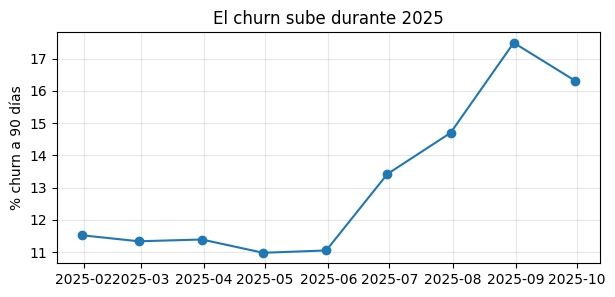

In [10]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(by_cutoff.index, by_cutoff["tasa"] * 100, marker="o")
ax.set_ylabel("% churn a 90 días"); ax.set_title("El churn sube durante 2025"); ax.grid(alpha=.3)
plt.show()

El churn pasa de ~11 % a ~17 % durante el año. Dos consecuencias para el diseño: la validación tiene que ser **temporal**
(entrenar con el pasado y evaluar en cortes posteriores, como ocurrirá en enero de 2026), y las probabilidades del modelo final
hay que **recalibrarlas** con los cortes más recientes, porque un modelo que promedia todo el año subestimaría el riesgo actual.

## 3. Texto de tickets: qué dice el cliente y en qué tono

Los 4.452 tickets usan solo **38 textos distintos**, y cerca de un tercio son **sarcásticos**
("Felicitaciones por la nueva versión, ahora la app se cierra sola… Genial"). De cada texto interesan cuatro cosas:
el **tema**, si el cliente **amenaza con irse**, y si está **molesto** (con enojo directo o con ironía).

**Qué se probó y por qué se eligió esta combinación** (detalle en `BITACORA_IA.md`), contra una referencia manual de los 38 textos:

| Enfoque | Resultado | ¿Se usa? |
|---|---|---|
| strands-decider (modelo de decisión de 2B, local): tema entre 8 opciones | 38/38 | Sí |
| strands-decider: ¿amenaza con irse? | 37/38 | Sí |
| strands-decider: sarcasmo / "¿está molesto?" (3 redacciones) | detecta 1-3 de 10 sarcásticos | No |
| pysentimiento (modelos en español): ironía | ordena perfecto (AUC 1,0); con corte 0,5 detecta 5/10 sin falsos positivos | Sí |
| pysentimiento: emoción "ira" | detecta 8 de 9 enojos directos | Sí |
| pysentimiento: sentimiento negativo | AUC 0,49: el sarcasmo sale "positivo" | No |
| TF-IDF / NLP clásico | con 38 textos únicos sería una tabla de búsqueda; el csat sigue al tema y no al tono, así que tampoco sirve como etiqueta débil | No |

**Regla:** `molesto = ira o ironía > 0,5`. El 0,5 es el corte natural del modelo; bajar el corte a ~0,1 detectaría 17/18 molestos,
pero sería ajustarlo mirando los mismos 38 textos con que se evalúa.

**Límites:** la referencia es chica (38 textos, 10 sarcásticos) y es un juicio humano; las probabilidades de ironía son poco graduadas;
strands-decider es una librería experimental. En producción, un texto nuevo se clasifica en vivo y si la confianza es baja va a revisión humana.

**Reproducibilidad:** la clasificación se calcula una vez, se revisa a mano y se guarda en `data_derivada/tickets_clasificados.csv`,
indexada por un hash del texto (el repositorio no publica textos de clientes). Con `RECALCULATE_NLP = True` se regenera en Colab
(instala strands-decider y pysentimiento y levanta el servidor del modelo; tarda unos minutos).

In [11]:
from conecta.tickets import DECIDER_MODEL, classify_texts, hash_text, load_classification

RECALCULATE_NLP = False
CLASSIFICATION_PATH = Path("data_derivada/tickets_clasificados.csv")

if RECALCULATE_NLP:
    import time, urllib.request
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "strands-decider", "pysentimiento"], check=True)
    server = subprocess.Popen(["strands-decider", "serve", DECIDER_MODEL, "--port", "8765"],
                              stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    for _ in range(180):  # hasta 15 minutos para descargar y calentar el modelo
        try:
            urllib.request.urlopen("http://127.0.0.1:8765/health", timeout=5); break
        except Exception:
            time.sleep(5)
    try:
        classify_texts(data.tickets["text"].dropna().unique().tolist()).to_csv(CLASSIFICATION_PATH, index=False)
    finally:
        server.terminate()

classification = load_classification(CLASSIFICATION_PATH)
data.tickets["hash"] = data.tickets["text"].map(hash_text, na_action="ignore")
coverage = data.tickets["hash"].isin(classification["hash"]).mean()
print(f"Textos clasificados: {len(classification)} | tickets cubiertos por la clasificación: {coverage:.1%}")

Textos clasificados: 38 | tickets cubiertos por la clasificación: 100.0%


In [12]:
# ¿Coincide el tema que asigna el modelo con la categoría que registró la plataforma? (validación independiente)
tk = data.tickets.merge(classification, on="hash", how="left")
pd.crosstab(tk["source_topic"], tk["topic"])

topic,acceso_cuenta,app_se_cierra,aumento_precio,cambio_plan,cancelar,cobro_doble,cobro_no_reconocido,lentitud
source_topic,,,,,,,,
app_se_cierra,0,816,0,0,0,0,0,0
cambio_clave,640,0,0,0,0,0,0,0
cambio_plan,0,0,0,328,0,0,0,0
cancelar,0,0,0,0,722,0,0,0
cobro_doble,0,0,0,0,0,699,0,0
lentitud,0,0,0,0,0,0,0,876
no_reconoce_cobro,0,0,175,0,0,0,196,0


El tema que asigna el modelo coincide con la categoría de la plataforma en todos los casos, salvo uno que **agrega información**:
lo que la plataforma registra como `no_reconoce_cobro` es en realidad de dos tipos. Casi la mitad son quejas por el
**aumento de precio sin aviso** ("Me subieron la tarifa sin avisar…"). La plataforma no distingue ese motivo; el texto sí.

In [13]:
summary = tk.groupby("topic").agg(tickets=("ticket_id", "size"), amenaza=("p_threat", lambda s: (s > .5).mean()),
                                  molesto=("annoyed", "mean"), csat=("csat", "mean"))
summary.sort_values("tickets", ascending=False).style.format({"amenaza": "{:.0%}", "molesto": "{:.0%}", "csat": "{:.2f}"})

,tickets,amenaza,molesto,csat
topic,,,,
lentitud,876,0%,29%,3.36
app_se_cierra,816,18%,56%,2.48
cancelar,722,100%,17%,3.72
cobro_doble,699,12%,60%,2.79
acceso_cuenta,640,0%,0%,3.31
cambio_plan,328,33%,0%,3.42
cobro_no_reconocido,196,0%,0%,3.40
aumento_precio,175,0%,100%,3.46


## 4. Variables: qué sabía la empresa de cada cliente en la fecha de corte

Cada variable se calcula **solo con lo que se sabía en el corte** (funciones de `conecta/features.py`, cada una con su prueba de fuga en `tests/test_features.py`):

| Bloque | Variables | Regla contra fugas |
|---|---|---|
| Cliente | antigüedad, segmento, ciudad, edad (+ indicador de edad inválida), canal, plataforma | `estado_actual` **no se usa** |
| Suscripción | plan vigente, días en el plan, suscripciones previas, cambios de plan | solo suscripciones iniciadas antes del corte |
| Facturación | pagos tarde (90/180 días), vencidas sin pagar, cobros dobles (total y 90 días), mensualidad, débito automático, afectado por el aumento del Básico | solo facturas **cargadas** antes del corte; un pago posterior al corte cuenta como impago |
| Uso de la app | logins 30/90 días y tendencia, eventos, errores, tasa de errores, cierres al abrir, funcionalidades usadas, usa la 5.2.0, días desde el último uso | fecha local ≤ corte |
| Tickets | tickets 30/90 días, por tema, molestos, amenazas, abiertos, csat promedio, días desde el último | el csat solo cuenta si el ticket ya estaba resuelto en el corte |
| Retención | contactado antes, días desde el contacto | solo contactos con fecha ≤ corte |

Clientes sin eventos o sin tickets quedan con conteos en 0 y un indicador (`no_events`, `no_tickets`), no se descartan.
Un detalle de los logs: empiezan el 1-ene-2025, así que en los cortes de enero y febrero las ventanas de 90 días están incompletas.

In [14]:
from conecta.features import build_matrix, build_panel

panel = build_panel(data, classification, labels)
score_ids = pd.Index(data.to_score["cliente_id"], name="cliente_id")
X_score = build_matrix(data, classification, TODAY, score_ids)
print(f"Panel de entrenamiento: {panel.shape} | matriz a puntuar (31-dic-2025): {X_score.shape}")
assert len(panel) == 13600 and len(X_score) == 1556 and X_score["plan"].notna().all()
nulls = panel.isna().mean()
nulls[nulls > 0].sort_values(ascending=False).to_frame("% nulos").style.format("{:.1%}")

Panel de entrenamiento: (13600, 54) | matriz a puntuar (31-dic-2025): (1556, 51)


,% nulos
days_since_contact,98.5%
csat_mean,50.6%
days_since_last_ticket,47.5%
error_rate_90d,2.6%
days_since_last_event,2.6%
age,2.3%


In [15]:
# Primera mirada: churn según algunas señales (sin controlar por nada todavía)
looks = {
    "ticket 'cancelar' (90 días)": panel["topic_cancelar_90d"] > 0,
    "usa la app 5.2.0": panel["uses_v520"] == 1,
    "cobro doble (90 días)": panel["duplicate_charges_90d"] > 0,
    "ticket molesto (90 días)": panel["annoyed_90d"] > 0,
    "factura vencida sin pagar": panel["overdue_unpaid"] > 0,
    "sin uso de la app": panel["no_events"] == 1,
}
pd.DataFrame({k: {"filas": int(m.sum()), "churn si": panel.loc[m, "churn_90d"].mean(), "churn no": panel.loc[~m, "churn_90d"].mean()}
              for k, m in looks.items()}).T.style.format({"churn si": "{:.1%}", "churn no": "{:.1%}", "filas": "{:,.0f}"})

,filas,churn si,churn no
ticket 'cancelar' (90 días),66,100.0%,12.9%
usa la app 5.2.0,595,28.2%,12.7%
cobro doble (90 días),692,20.2%,13.0%
ticket molesto (90 días),974,17.2%,13.0%
factura vencida sin pagar,"4,302",15.6%,12.3%
sin uso de la app,349,29.5%,12.9%


Un ticket de "cancelar" en los últimos 90 días equivale a churn (100 % en el panel). Es una señal legítima (el ticket es anterior al corte),
pero es casi la cancelación misma: el modelo la va a usar, y para la decisión de negocio queda la pregunta de si llamar a ese cliente
rinde el 40 % que supone el enunciado (se discute en la sección 7).

## 5. Modelos: validación temporal y 4 corridas en MLflow

**Cómo se valida.** Se simula lo que habría pasado si el modelo se hubiera usado en julio, agosto y septiembre de 2025:
para evaluar en el corte E se entrena solo con cortes C ≤ E − 3 meses. La etiqueta de C se conoce en C + 90 días,
así que con esa separación toda etiqueta usada para entrenar ya existía el día E (`conecta/validation.py`).
No se usa validación cruzada aleatoria: un mismo cliente aparece en varios cortes y el churn cambia en el tiempo
(sube de 11 % a 17 % en el verano de 2025), así que mezclar filas al azar promete un desempeño que no se tendría en producción.

**Qué se mide.** AUC-PR y AUC (orden), Brier (calidad de la probabilidad) y, sobre todo, el **valor realizado**:
lo que habría producido contactar a quien la regla de negocio elige, con el churn que de verdad ocurrió
(Σ sobre contactados de churn·0,4·12·precio − 25.000). Se compara con no contactar a nadie (0), contactar a todos
y un oráculo que solo llama a quien se iba a ir (techo inalcanzable).

| Corrida | Modelo | Variables |
|---|---|---|
| `base` | Regresión logística | antigüedad, plan, pagos tarde, vencidas sin pagar, tickets 90 días |
| `gbm_full` | LightGBM | todas |
| `gbm_no_unstructured` | LightGBM | todas menos las de logs y tickets: mide cuánto aportan los datos no estructurados |
| `gbm_history_2023` | LightGBM | todas, con cortes desde mar-2023 (sin logs antes de 2025: NaN + `logs_available`) |

Los hiperparámetros del LightGBM son fijos y conservadores (`conecta/models.py`), elegidos antes de mirar los folds:
ajustarlos sobre los mismos tres meses de evaluación inflaría el resultado.

In [16]:
import shutil
import mlflow
from conecta.labels import build_labels, monthly_cutoffs
from conecta.validation import temporal_folds
from conecta.models import (BASE_FEATURES, CONTACT_FEATURES, EXPERIMENT, TRACKING_URI, UNSTRUCTURED_FEATURES,
                            evaluate_run, feature_columns, fit_model, log_run, nested_tuning)

# Panel largo para la corrida 4 (mismas reglas, cortes desde mar-2023)
labels_2023 = build_labels(data.subscriptions, monthly_cutoffs("2023-03-31", "2025-09-30"))
panel_2023 = build_panel(data, classification, labels_2023)

EVAL_CUTOFFS = [pd.Timestamp(c) for c in ["2025-07-31", "2025-08-31", "2025-09-30"]]
folds = temporal_folds(sorted(panel["cutoff"].unique()), EVAL_CUTOFFS)
folds_2023 = temporal_folds(sorted(panel_2023["cutoff"].unique()), EVAL_CUTOFFS)
for train, ev in folds:
    print(f"evalúa {ev:%Y-%m-%d} | entrena con {train[0]:%Y-%m} … {train[-1]:%Y-%m} ({len(train)} cortes)")

ALL = feature_columns(panel)
RUNS = {
    "base": (panel, folds, "base", BASE_FEATURES),
    "gbm_full": (panel, folds, "gbm", ALL),
    "gbm_no_unstructured": (panel, folds, "gbm", feature_columns(panel, UNSTRUCTURED_FEATURES)),
    "gbm_history_2023": (panel_2023, folds_2023, "gbm", ALL),
}

evalúa 2025-07-31 | entrena con 2025-01 … 2025-04 (4 cortes)
evalúa 2025-08-31 | entrena con 2025-01 … 2025-05 (5 cortes)
evalúa 2025-09-30 | entrena con 2025-01 … 2025-06 (6 cortes)


In [17]:
# Se parte de un registro limpio para que la tabla sea reproducible al re-ejecutar el notebook
for p in ["mlflow.db", "mlruns"]:
    shutil.rmtree(p, ignore_errors=True) if Path(p).is_dir() else Path(p).unlink(missing_ok=True)

results = {}
for name, (pnl, flds, kind, cols) in RUNS.items():
    results[name] = evaluate_run(pnl, flds, kind, cols)
    log_run(name, {"kind": kind, "n_features": len(cols), "features": cols, "calibration": "none",
                   "train_from": f"{pnl['cutoff'].min():%Y-%m}", "gap_months": 3}, results[name])
    print(f"{name:22s} valor realizado promedio: {results[name]['realized_value'] / 1e6:6.2f} M COP")

2026/11/21 01:30:34 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/21 01:30:34 INFO mlflow.store.db.utils: Updating database tables


2026/11/21 01:30:34 INFO mlflow.tracking.fluent: Experiment with name 'conecta-churn' does not exist. Creating a new experiment.


base                   valor realizado promedio:   5.91 M COP


gbm_full               valor realizado promedio:  13.06 M COP


gbm_no_unstructured    valor realizado promedio:   6.02 M COP


gbm_history_2023       valor realizado promedio:  13.94 M COP


In [18]:
mlflow.set_tracking_uri(TRACKING_URI)
runs = mlflow.search_runs(experiment_names=[EXPERIMENT], order_by=["metrics.realized_value DESC"])
cols_show = {"tags.mlflow.runName": "corrida", "params.calibration": "calibración", "metrics.auc_pr": "AUC-PR",
             "metrics.auc": "AUC", "metrics.brier": "Brier", "metrics.realized_value": "valor realizado",
             "metrics.realized_value_std": "desv. entre folds", "metrics.value_contact_all": "contactar a todos",
             "metrics.value_oracle": "oráculo", "metrics.n_contacted": "contactados/mes"}
board = runs[list(cols_show)].rename(columns=cols_show)
money = {c: (lambda v: f"{v / 1e6:,.1f} M") for c in ["valor realizado", "desv. entre folds", "contactar a todos", "oráculo"]}
board.style.format({"AUC-PR": "{:.3f}", "AUC": "{:.3f}", "Brier": "{:.3f}", "contactados/mes": "{:,.0f}", **money}).hide(axis="index")

corrida,calibración,AUC-PR,AUC,Brier,valor realizado,desv. entre folds,contactar a todos,oráculo,contactados/mes
gbm_history_2023,none,0.358,0.677,0.124,13.9 M,6.0 M,7.8 M,43.2 M,464
gbm_full,none,0.344,0.665,0.126,13.1 M,6.0 M,7.8 M,43.2 M,427
gbm_no_unstructured,none,0.275,0.578,0.133,6.0 M,3.5 M,7.8 M,43.2 M,329
base,none,0.195,0.558,0.137,5.9 M,3.8 M,7.8 M,43.2 M,269


In [19]:
# Detalle por fold: ¿la ventaja se sostiene en los tres meses o depende de uno?
detail = pd.concat({n: r["per_fold"].set_index("cutoff")[["churn_rate", "mean_p", "auc", "realized_value"]]
                    for n, r in results.items()}, axis=1)
detail.index = detail.index.strftime("%Y-%m")
detail.style.format({c: (lambda v: f"{v / 1e6:,.1f} M") if c[1] == "realized_value" else "{:.3f}" for c in detail.columns})

**Lectura.**
- Los datos no estructurados son lo que más aporta: el mismo LightGBM sin logs ni tickets vale aproximadamente la mitad (`gbm_no_unstructured` vs `gbm_full`).
  La regresión base ni siquiera supera a "contactar a todos".
- El desempeño mejora fold a fold (AUC de ~0,61 en julio a ~0,74 en septiembre). El motivo: el problema de la 5.2.0 (sección 8)
  empieza en junio, y el modelo solo puede aprenderlo cuando ese mes entra al entrenamiento. Es el argumento para reentrenar cada mes.
- La probabilidad promedio queda por debajo del churn real (`mean_p` < `churn_rate`): el modelo aprendió de meses con menos churn.
  Como la decisión compara probabilidades contra umbrales absolutos, eso hace que se contacte de menos.

In [20]:
# Calibración con el corte reciente: Platt sobre el último corte de entrenamiento, puntuado por un modelo que no lo vio.
# Se prueba sobre las dos mejores corridas y se registra como corridas adicionales.
for name in ["gbm_full", "gbm_history_2023"]:
    pnl, flds, kind, cols = RUNS[name]
    results[f"{name}_calibrated"] = evaluate_run(pnl, flds, kind, cols, calibration="recent")
    log_run(f"{name}_calibrated", {"kind": kind, "n_features": len(cols), "features": cols, "calibration": "recent",
                                   "train_from": f"{pnl['cutoff'].min():%Y-%m}", "gap_months": 3},
            results[f"{name}_calibrated"])
cmp = pd.DataFrame({n: results[n]["per_fold"].set_index("cutoff")["realized_value"] / 1e6
                    for n in ["gbm_full", "gbm_full_calibrated", "gbm_history_2023", "gbm_history_2023_calibrated"]})
cmp.index = cmp.index.strftime("%Y-%m")
cmp.loc["promedio"] = cmp.mean()
cmp.style.format("{:.1f} M")

,gbm_full,gbm_full_calibrated,gbm_history_2023,gbm_history_2023_calibrated
cutoff,,,,
2025-07,7.1 M,7.8 M,7.6 M,7.2 M
2025-08,13.0 M,14.1 M,14.6 M,14.1 M
2025-09,19.1 M,19.1 M,19.6 M,20.3 M
promedio,13.1 M,13.6 M,13.9 M,13.9 M


In [21]:
# Registro completo en MLflow: las 6 corridas
runs = mlflow.search_runs(experiment_names=[EXPERIMENT], order_by=["metrics.realized_value DESC"])
runs[list(cols_show)].rename(columns=cols_show).style.format(
    {"AUC-PR": "{:.3f}", "AUC": "{:.3f}", "Brier": "{:.3f}", "contactados/mes": "{:,.0f}", **money}).hide(axis="index")

corrida,calibración,AUC-PR,AUC,Brier,valor realizado,desv. entre folds,contactar a todos,oráculo,contactados/mes
gbm_history_2023,none,0.358,0.677,0.124,13.9 M,6.0 M,7.8 M,43.2 M,464
gbm_history_2023_calibrated,recent,0.358,0.677,0.124,13.9 M,6.6 M,7.8 M,43.2 M,561
gbm_full_calibrated,recent,0.344,0.665,0.126,13.6 M,5.6 M,7.8 M,43.2 M,558
gbm_full,none,0.344,0.665,0.126,13.1 M,6.0 M,7.8 M,43.2 M,427
gbm_no_unstructured,none,0.275,0.578,0.133,6.0 M,3.5 M,7.8 M,43.2 M,329
base,none,0.195,0.558,0.137,5.9 M,3.8 M,7.8 M,43.2 M,269


In [22]:
# Regla de selección: mayor valor realizado promedio; si la diferencia con la más simple no supera su variación
# entre folds (comparación pareada mes a mes), gana la más simple.
def paired(a, b):
    d = results[a]["per_fold"]["realized_value"].to_numpy() - results[b]["per_fold"]["realized_value"].to_numpy()
    return pd.Series({"diferencia promedio (M)": d.mean() / 1e6, "desv. de la diferencia (M)": d.std(ddof=1) / 1e6,
                      "meses en que gana": f"{(d > 0).sum()} de {len(d)}"})

pd.DataFrame({"gbm_full vs sin no estructurados": paired("gbm_full", "gbm_no_unstructured"),
              "historial 2023 vs gbm_full": paired("gbm_history_2023", "gbm_full"),
              "gbm_full: calibrado vs sin calibrar": paired("gbm_full_calibrated", "gbm_full"),
              "historial 2023: calibrado vs sin calibrar": paired("gbm_history_2023_calibrated", "gbm_history_2023")}).T

,diferencia promedio (M),desv. de la diferencia (M),meses en que gana
gbm_full vs sin no estructurados,7.042813,3.710553,3 de 3
historial 2023 vs gbm_full,0.879933,0.612451,3 de 3
gbm_full: calibrado vs sin calibrar,0.572173,0.577194,2 de 3
historial 2023: calibrado vs sin calibrar,-0.06196,0.688805,1 de 3


**Elección (de familia de modelo): `gbm_history_2023`, sin calibrar.** El tratamiento de las llamadas de retención se decide en la sección 6.
- Frente a `gbm_no_unstructured` la ventaja de usar logs y texto es grande y se repite en los tres meses: los datos no estructurados se quedan.
- `gbm_history_2023` supera a `gbm_full` en los tres meses. La diferencia es chica (menos de 1 M COP al mes), pero es consistente,
  así que por la regla fijada de antemano gana. Antes de verlo esperaba lo contrario: que dos años sin logs no aportaran. Sí aportan,
  porque esos meses enseñan los patrones de facturación, tickets y antigüedad con mucha más muestra.
- La calibración con el corte reciente **no se adopta**: en el modelo elegido mejora un solo mes de tres. Un Platt ajustado sobre
  un solo mes (~1.500 clientes) es ruidoso, y el corte más reciente disponible para entrenar no refleja todavía la subida del churn.
  La probabilidad queda algo por debajo del churn real, lo que hace a la regla conservadora (se contacta de menos, no de más).
  Para producción se propone recalibrar cuando haya más meses del nuevo régimen (sección 9).

Límite honesto: un AUC de 0,62–0,75 es un ordenamiento modesto. El modelo no "adivina" quién se va. Lo que muestra el backtest
es que, aun así, concentra las llamadas donde rinden: el valor realizado es cerca del doble de contactar a todos.

In [23]:
# ¿Ajustar hiperparámetros mejora el valor? Ajuste anidado: en cada fold se eligen los parámetros con datos anteriores
# (validación interna en el último corte de entrenamiento). Se compara con los parámetros fijos y con el mejor en retrospectiva.
import itertools
GRID = [dict(n_estimators=n, learning_rate=lr, num_leaves=nl, min_child_samples=mcs)
        for n, lr, nl, mcs in itertools.product([150, 800], [0.02, 0.05], [7, 31], [20, 80])]
tuning = nested_tuning(panel_2023, folds_2023, ALL, GRID)
tuning_view = tuning.assign(cutoff=tuning["cutoff"].dt.strftime("%Y-%m"))
tuning_view.loc["promedio"] = ["", "", *tuning[["value_default", "value_tuned", "value_best_hindsight"]].mean()]
tuning_view.style.format({c: (lambda v: f"{v / 1e6:,.1f} M" if v != "" else "") for c in ["value_default", "value_tuned", "value_best_hindsight"]})

,cutoff,chosen_params,value_default,value_tuned,value_best_hindsight
0,2025-07,"{'n_estimators': 800, 'learning_rate': 0.05, 'num_leaves': 31, 'min_child_samples': 20}",7.6 M,3.5 M,9.7 M
1,2025-08,"{'n_estimators': 800, 'learning_rate': 0.02, 'num_leaves': 31, 'min_child_samples': 20}",14.6 M,11.4 M,16.3 M
2,2025-09,"{'n_estimators': 150, 'learning_rate': 0.02, 'num_leaves': 7, 'min_child_samples': 80}",19.6 M,16.2 M,20.8 M
promedio,,,13.9 M,10.3 M,15.6 M


**Ajustar hiperparámetros no mejora: empeora.** La validación interna elige configuraciones distintas cada mes (ruido, no señal) y
el valor fuera de muestra baja frente a los parámetros fijos. Aun eligiendo con trampa la mejor de 16 mirando el resultado, la ganancia
es pequeña. El límite está en la información que hay en los datos, no en la configuración del modelo; se mantienen los parámetros fijos.

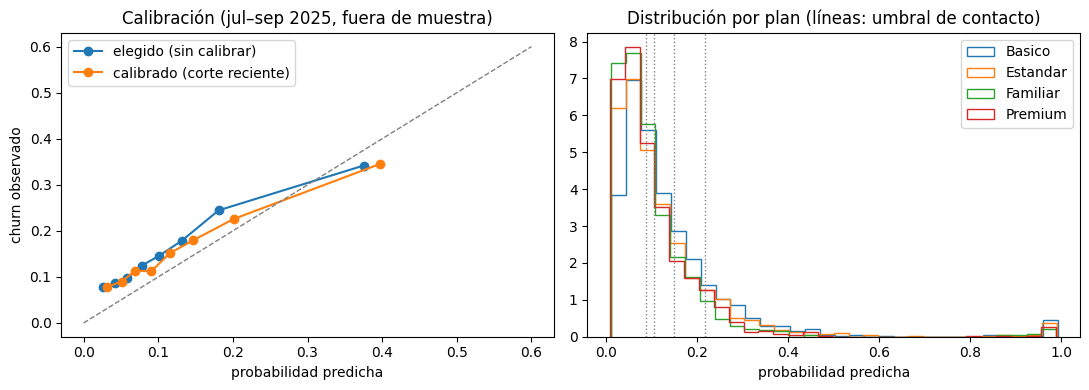

In [24]:
from sklearn.calibration import calibration_curve

CHOSEN = "gbm_history_2023"
chosen = results[CHOSEN]["predictions"]
cal_p = results[f"{CHOSEN}_calibrated"]["predictions"]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for label, pr in [("elegido (sin calibrar)", chosen), ("calibrado (corte reciente)", cal_p)]:
    frac, mean_pred = calibration_curve(pr["churn_90d"], pr["p"], n_bins=8, strategy="quantile")
    ax[0].plot(mean_pred, frac, marker="o", label=label)
ax[0].plot([0, .6], [0, .6], ls="--", c="grey", lw=1)
ax[0].set(xlabel="probabilidad predicha", ylabel="churn observado", title="Calibración (jul–sep 2025, fuera de muestra)")
ax[0].legend()
for plan, g in chosen.groupby("plan"):
    ax[1].hist(g["p"], bins=30, histtype="step", label=plan, density=True)
from conecta.business import threshold
for plan in chosen["plan"].unique():
    ax[1].axvline(threshold(plan), ls=":", lw=1, c="grey")
ax[1].set(xlabel="probabilidad predicha", title="Distribución por plan (líneas: umbral de contacto)")
ax[1].legend()
plt.tight_layout()

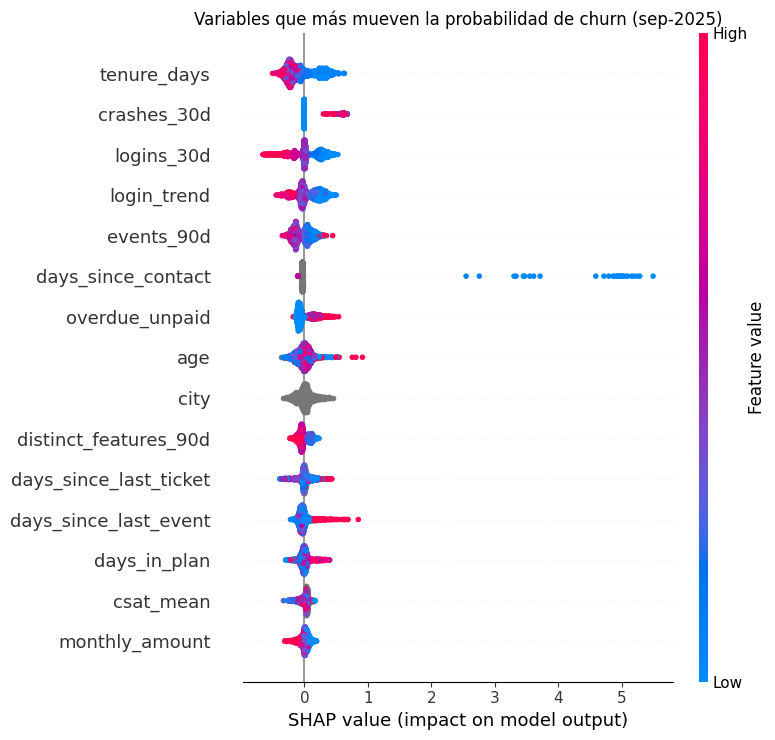

In [25]:
import shap
warnings.filterwarnings("ignore", category=UserWarning, module="shap")

# Importancia global con SHAP: modelo elegido del último fold (entrenado hasta jun-2025) explicando el corte de septiembre
train_last, ev_last = folds_2023[-1]
m_last = fit_model(panel_2023, train_last, "gbm", ALL).model
X_ev = m_last["cat"].transform(panel_2023.loc[panel_2023["cutoff"] == ev_last, ALL])
shap_values = shap.TreeExplainer(m_last["clf"]).shap_values(X_ev)
shap.summary_plot(shap_values, X_ev, max_display=15, show=False)
plt.title("Variables que más mueven la probabilidad de churn (sep-2025)")
plt.tight_layout()

Las variables que más mueven la probabilidad son la **antigüedad** (los clientes nuevos se van más) y el **uso de la app**:
cierres al abrir en los últimos 30 días, logins recientes y su tendencia. Que `crashes_30d` aparezca segunda es la huella del
problema de la versión 5.2.0 (sección 8). Después vienen la facturación (vencidas sin pagar) y los tickets.

Ojo con `days_since_contact`: pesa porque el equipo de retención llamaba a quien ya se estaba yendo. El modelo aprende
"me llamaron hace poco → me voy", que es correlación de selección, no un efecto de la llamada. Se analiza en la sección 6.

## 6. Efecto de las llamadas de retención

Las etiquetas reflejan la política de llamadas de entonces: si una llamada retuvo a alguien, ese cliente quedó con
etiqueta 0 aunque iba a irse, y el modelo aprendería que "ese perfil no se va". Antes de entrenar el modelo final hay que
saber cuánto pesa eso. La pregunta tiene tres partes: qué es una llamada en estos datos, cuánto contamina las etiquetas
y cómo tratarla en el modelo.

`clientes` solo guarda la **última** llamada de cada cliente. Una llamada se juzga a 90 días; si fue hace menos de 90 días
y el cliente sigue activo, queda como *censurada* (todavía no se sabe), no como retenida.

In [26]:
from conecta.retention import contact_outcomes, team_contacted

outcomes = contact_outcomes(data.clients, data.subscriptions, TODAY)
judged = outcomes[~outcomes["censored"]]
print(f"Clientes contactados: {len(outcomes):,} | censurados (llamada reciente, aún activos): {outcomes['censored'].sum()}")
print(f"Se fueron dentro de 90 días: {judged['churned_90d'].mean():.1%} | retenidos: {judged['retained'].sum()} ({judged['retained'].mean():.1%})")
d2c = outcomes["days_to_churn"].dropna()
print(f"Días entre la llamada y la baja: mediana {d2c.median():.0f}, mínimo {d2c.min():.0f}, máximo {d2c.max():.0f}")

by_year = judged.groupby(judged["contact_date"].dt.year).agg(llamadas=("retained", "size"), retenidos=("retained", "sum"),
                                                            tasa_retención=("retained", "mean"))
by_year.style.format({"tasa_retención": "{:.1%}"})

Clientes contactados: 930 | censurados (llamada reciente, aún activos): 22
Se fueron dentro de 90 días: 98.0% | retenidos: 18 (2.0%)
Días entre la llamada y la baja: mediana 11, mínimo 3, máximo 19


,llamadas,retenidos,tasa_retención
contact_date,,,
2023,71,0,0.0%
2024,268,0,0.0%
2025,569,18,3.2%


In [27]:
# ¿Qué pasó antes de la llamada? Tickets en los 30 días previos
tk_prev = tk.merge(outcomes[["cliente_id", "contact_date"]], on="cliente_id")
day = tk_prev["created_at"].dt.normalize()
tk_prev = tk_prev[(day <= tk_prev["contact_date"]) & (day > tk_prev["contact_date"] - pd.Timedelta(days=30))]
pd.Series({
    "con cualquier ticket": tk_prev["cliente_id"].nunique() / len(outcomes),
    "con ticket de 'cancelar'": tk_prev.loc[tk_prev["topic"] == "cancelar", "cliente_id"].nunique() / len(outcomes),
    "con amenaza de irse": tk_prev.loc[tk_prev["p_threat"] > .5, "cliente_id"].nunique() / len(outcomes),
}, name="% de llamadas con … en los 30 días previos").to_frame().style.format("{:.1%}")

,% de llamadas con … en los 30 días previos
con cualquier ticket,28.3%
con ticket de 'cancelar',16.3%
con amenaza de irse,17.4%


**Qué es una llamada de retención aquí.** No es una campaña: es un paso del proceso de baja. Todas las bajas posteriores
a una llamada ocurren entre 3 y 19 días después, y solo ~1 de cada 6 llamadas viene precedida de un ticket de cancelar:
el aviso llega por otro canal (probablemente la solicitud de baja). En 2023 y 2024 la llamada no retuvo a nadie; en 2025,
a ~3 %. Con el costo de 25.000 COP, una llamada así necesita retener al menos ~6 % para no perder plata (tabla de abajo).

In [28]:
# ¿Cuánto contamina las etiquetas? Filas del panel con una llamada dentro de su ventana de 90 días
p23 = panel_2023.copy()
contact_date = p23["cliente_id"].map(data.clients.set_index("cliente_id")["fecha_contacto_retencion"])
p23["called_in_window"] = (contact_date > p23["cutoff"]) & (contact_date <= p23["cutoff"] + pd.Timedelta(days=90))
w = p23["called_in_window"]
print(f"Filas con llamada en la ventana: {w.sum():,} ({w.mean():.1%}) | churn entre ellas: {p23.loc[w, 'churn_90d'].mean():.0%}")
print(f"Casos de churn en el panel: {p23['churn_90d'].sum():,} | de ellos en filas llamadas: {p23.loc[w, 'churn_90d'].sum():,}")
print(f"Clientes retenidos por una llamada (cota de la contaminación): {judged['retained'].sum()} "
      f"= {judged['retained'].sum() / p23['churn_90d'].sum():.1%} de los casos de churn")

Filas con llamada en la ventana: 1,963 (7.5%) | churn entre ellas: 88%
Casos de churn en el panel: 3,164 | de ellos en filas llamadas: 1,721
Clientes retenidos por una llamada (cota de la contaminación): 18 = 0.6% de los casos de churn


In [29]:
# Cuatro formas de tratar las llamadas en el modelo elegido (mismos folds); se registran en MLflow
NO_CONTACT = [c for c in ALL if c not in CONTACT_FEATURES]
VARIANTS = {
    "calls_A_as_is": dict(columns=ALL, train_exclude=None),
    "calls_B_drop_called_rows": dict(columns=ALL, train_exclude=p23["called_in_window"]),
    "calls_C_no_contact_features": dict(columns=NO_CONTACT, train_exclude=None),
    "calls_D_both": dict(columns=NO_CONTACT, train_exclude=p23["called_in_window"]),
}
for name, v in VARIANTS.items():
    results[name] = evaluate_run(panel_2023, folds_2023, "gbm", v["columns"], train_exclude=v["train_exclude"])
    log_run(name, {"kind": "gbm", "n_features": len(v["columns"]), "features": v["columns"], "calibration": "none",
                   "train_from": "2023-03", "gap_months": 3, "drop_called_rows": v["train_exclude"] is not None},
            results[name])
calls = pd.DataFrame({n: {k: results[n][k] for k in ["auc", "mean_p", "realized_value", "n_contacted", "n_in_process",
                                                      "realized_value_actionable", "value_contact_all_actionable"]}
                      for n in VARIANTS}).T
calls.columns = ["AUC", "prob. media", "valor realizado", "contactos/mes", "contactos ya en proceso de baja",
                 "valor accionable", "contactar a todos (accionable)"]
m = lambda v: f"{v / 1e6:,.1f} M"
calls.style.format({"AUC": "{:.3f}", "prob. media": "{:.3f}", "valor realizado": m, "valor accionable": m,
                    "contactar a todos (accionable)": m, "contactos/mes": "{:,.0f}", "contactos ya en proceso de baja": "{:,.0f}"})

,AUC,prob. media,valor realizado,contactos/mes,contactos ya en proceso de baja,valor accionable,contactar a todos (accionable)
calls_A_as_is,0.677,0.124,13.9 M,464,27,10.3 M,4.1 M
calls_B_drop_called_rows,0.666,0.056,6.3 M,102,27,2.7 M,4.1 M
calls_C_no_contact_features,0.668,0.120,13.7 M,491,20,10.7 M,4.1 M
calls_D_both,0.659,0.055,5.5 M,123,13,3.6 M,4.1 M


"En proceso de baja" = el equipo lo llamó en los últimos 30 días o tiene un ticket de cancelar en los últimos 90
(`in_cancellation_process` en `conecta/business.py`). El valor *accionable* excluye a esos clientes de la lista.

**Decisión (aprobada por el candidato):**
1. **No se corrigen las etiquetas.** La contaminación es menor al 1 % de los casos de churn. Y la corrección por exclusión (B)
   hace daño: como las llamadas siguen al churn, quitar las filas llamadas borra más de la mitad de los positivos, la probabilidad
   se desploma y el valor cae a la mitad. La "corrección" mete un sesgo mucho mayor que el que corrige.
2. **Se quitan `contacted_before` y `days_since_contact` del modelo final (C).** Vale prácticamente lo mismo y deja de depender de
   la política actual: si el equipo cambia cómo llama (o lo reemplaza este modelo), esas variables cambian de significado.
3. **No se recomienda contactar a quien ya está en proceso de baja.** Ya lo atiende el flujo actual, y para él suponer una retención
   del 40 % no tiene sustento: el 95 % se va igual. Por eso el valor que se reporta es el **accionable**, no el de la regla pura.

In [30]:
# Modelo (variante C) contra lo que hace hoy el equipo, mes a mes
from conecta.business import break_even_effectiveness, realized_value
FINAL_COLUMNS = NO_CONTACT
pred = results["calls_C_no_contact_features"]["predictions"]
rows = []
for ev, g in pred.groupby("cutoff"):
    team = team_contacted(data.clients, ev, g["cliente_id"]).to_numpy()
    top100 = (g["p"].where(~g["in_process"]).rank(ascending=False, method="first") <= 100).to_numpy()
    for name, sel in [("equipo hoy (llamadas del mes siguiente)", team),
                      ("modelo: regla, sin los ya en proceso", g["contact_actionable"].to_numpy().astype(bool)),
                      ("modelo: top 100, sin los ya en proceso", top100)]:
        rows.append({"mes": f"{ev:%Y-%m}", "estrategia": name, "llamadas": int(sel.sum()),
                     "% que se iba": g.loc[sel, "churn_90d"].mean(),
                     "gasto (M)": sel.sum() * 25_000 / 1e6,
                     **{f"neto si retiene {int(e * 100)} % (M)": realized_value(sel, g["churn_90d"], g["plan"], effectiveness=e) / 1e6
                        for e in (0.4, 0.2, 0.1, 0.03)},
                     "efectividad de equilibrio": break_even_effectiveness(sel, g["churn_90d"], g["plan"])})
vs_team = pd.DataFrame(rows).groupby("estrategia", sort=False).mean(numeric_only=True)
vs_team.style.format({c: ("{:.0f}" if c == "llamadas" else "{:.0%}" if c in ("% que se iba", "efectividad de equilibrio")
                         else "{:.1f}") for c in vs_team.columns})

,llamadas,% que se iba,gasto (M),neto si retiene 40 % (M),neto si retiene 20 % (M),neto si retiene 10 % (M),neto si retiene 3 % (M),efectividad de equilibrio
estrategia,,,,,,,,
equipo hoy (llamadas del mes siguiente),58,98%,1.5,8.8,3.7,1.1,-0.7,6%
"modelo: regla, sin los ya en proceso",472,23%,11.8,10.7,-0.5,-6.2,-10.1,21%
"modelo: top 100, sin los ya en proceso",100,30%,2.5,2.3,-0.1,-1.3,-2.1,21%


**Lectura para la gerencia.**
- El equipo apunta "mejor" que el modelo (casi todos los que llama se iban), pero porque llama cuando la baja ya está en curso.
  Esas llamadas retienen ~3 % (columna "neto si retiene 3 %"), por debajo del ~6 % que necesitan: hoy se gasta poco y se pierde un poco.
- El modelo llama con meses de anticipación, a más gente y con menos certeza (~1 de cada 4 a 3 de cada 10 contactados se iba).
  Necesita que la llamada temprana retenga al menos ~21 %. Si retiene el 40 % del enunciado, gana ~10 M COP al mes; si retiene 10 %,
  pierde. **Los datos no dicen cuál de los dos casos es**, porque nunca se llamó temprano.
- Por eso la recomendación no es reemplazar al equipo de un día para otro, sino un **piloto con grupo de control**: los 100 de mayor
  riesgo (fuera del flujo de baja), se llama a la mitad y se compara con la otra mitad durante 2–3 meses. Cuesta lo mismo que el equipo
  hoy y mide la única cifra que falta. Se escala si la efectividad medida supera la de equilibrio (~21 %).